# SOC Log Investigation
**Synthetic authentication log — defensive exercise only.**  
Fictional accounts · Documentation-range IPs (RFC 5737) · No external systems contacted.

---

## 0 — Discover the CSV
Inspect column names, dtypes, and missing values without assuming the schema.

In [1]:
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.backends.backend_pdf import PdfPages
import warnings, re, os
warnings.filterwarnings('ignore')

CSV_PATH = r'c:\\video\\auth_log.csv'

# Load raw; discover columns
raw = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
print("=== RAW SCHEMA ===")
print(f"Rows (data only): {len(raw)}  |  Columns: {list(raw.columns)}")
for col in raw.columns:
    print(f"  {col}: {raw[col].dtype}")
print()
print("=== MISSING VALUES (empty string) ===")
empty_counts = (raw == '').sum()
for col, cnt in empty_counts.items():
    print(f"  {col}: {cnt}")
print()
print("=== SAMPLE (first 5 rows) ===")
print(raw.head().to_string())


=== RAW SCHEMA ===
Rows (data only): 473  |  Columns: ['timestamp', 'username', 'source_ip', 'action', 'result']
  timestamp: object
  username: object
  source_ip: object
  action: object
  result: object

=== MISSING VALUES (empty string) ===
  timestamp: 2
  username: 3
  source_ip: 3
  action: 2
  result: 2

=== SAMPLE (first 5 rows) ===
                 timestamp username   source_ip action   result
0  2024-03-15 02:01:12 UTC   jsmith  192.0.2.10  LOGIN  FAILURE
1  2024-03-15 02:04:48 UTC   jsmith  192.0.2.10  LOGIN  FAILURE
2  2024-03-15 02:08:24 UTC   jsmith  192.0.2.10  LOGIN  FAILURE
3  2024-03-15 02:12:00 UTC   jsmith  192.0.2.10  LOGIN  FAILURE
4  2024-03-15 02:15:36 UTC   jsmith  192.0.2.10  LOGIN  FAILURE


## 1 — Normalize
Parse timestamps → UTC, clean usernames, validate IPs, standardize result values, remove duplicates.

In [1]:
df = raw.copy()

# Discover column names dynamically (do not assume)
COL_TS, COL_USER, COL_IP, COL_ACTION, COL_RESULT = df.columns[:5]
print(f"Columns mapped: ts={COL_TS}, user={COL_USER}, ip={COL_IP}, action={COL_ACTION}, result={COL_RESULT}")

# 1.1 Drop fully empty rows
empty_mask = (df == '').all(axis=1)
n_empty = int(empty_mask.sum())
df = df[~empty_mask].copy()
print(f"Dropped {n_empty} fully empty rows")

# 1.2 Parse timestamps (try multiple formats)
def parse_ts(val):
    for fmt in ('%Y-%m-%dT%H:%M:%SZ', '%Y-%m-%d %H:%M:%S UTC',
                '%Y-%m-%dT%H:%M:%S+00:00', '%Y-%m-%dT%H:%M:%S'):
        try:
            return pd.to_datetime(val, format=fmt, utc=True)
        except Exception:
            pass
    return pd.NaT

df['ts_parsed'] = df[COL_TS].apply(parse_ts)
n_bad_ts = int(df['ts_parsed'].isna().sum())
print(f"Unparseable timestamps: {n_bad_ts}")
df = df[df['ts_parsed'].notna()].copy()

# 1.3 Clean username: strip whitespace, lowercase
df['username_clean'] = df[COL_USER].str.strip().str.lower()
n_blank_user = int((df['username_clean'] == '').sum())
print(f"Rows with blank username after strip: {n_blank_user}")

# 1.4 Validate IP addresses
IP_RE = re.compile(r'^(\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3})$')
def valid_ip(ip):
    if not isinstance(ip, str): return False
    m = IP_RE.match(ip.strip())
    if not m: return False
    return all(0 <= int(p) <= 255 for p in ip.strip().split('.'))
df['ip_valid'] = df[COL_IP].apply(valid_ip)
n_bad_ip = int((~df['ip_valid']).sum())
print(f"Invalid/missing IP rows: {n_bad_ip}")

# 1.5 Standardize result -> SUCCESS / FAILURE
SUCCESS_VALS = {'success', 'succeeded', 'ok', '200'}
FAILURE_VALS = {'failure', 'failed', 'fail', 'error', 'denied', '401', '403'}
def std_result(val):
    v = str(val).strip().lower()
    if v in SUCCESS_VALS: return 'SUCCESS'
    if v in FAILURE_VALS: return 'FAILURE'
    return 'UNKNOWN'
df['result_std'] = df[COL_RESULT].apply(std_result)
n_unknown = int((df['result_std'] == 'UNKNOWN').sum())
print(f"Unknown result values: {n_unknown}")

# 1.6 Remove exact duplicates
n_before = len(df)
df = df.drop_duplicates(subset=[COL_TS, COL_USER, COL_IP, COL_RESULT])
n_dupes = n_before - len(df)
print(f"Duplicate rows removed: {n_dupes}")

# 1.7 Build clean frame
df_clean = df[['ts_parsed','username_clean','ip_valid',
               COL_IP, COL_ACTION, 'result_std']].rename(columns={
    'ts_parsed': 'timestamp', 'username_clean': 'username',
    COL_IP: 'source_ip', COL_ACTION: 'action', 'result_std': 'result',
})
df_clean = df_clean[df_clean['ip_valid'] & (df_clean['username'] != '')].drop(columns='ip_valid')

total_rows = len(df_clean)
total_fail = int((df_clean['result']=='FAILURE').sum())
total_succ = int((df_clean['result']=='SUCCESS').sum())

print()
print("=== DATA QUALITY SUMMARY ===")
print(f"Raw rows loaded          : {len(raw)}")
print(f"Fully empty rows dropped : {n_empty}")
print(f"Bad timestamp rows       : {n_bad_ts}")
print(f"Invalid/missing IP rows  : {n_bad_ip}")
print(f"Duplicate rows removed   : {n_dupes}")
print(f"Unknown result values    : {n_unknown}")
print(f"Clean rows remaining     : {total_rows}")
print()
print(df_clean.head(10).to_string())


Columns mapped: ts=timestamp, user=username, ip=source_ip, action=action, result=result
Dropped 2 fully empty rows
Unparseable timestamps: 0
Rows with blank username after strip: 1
Invalid/missing IP rows: 2
Unknown result values: 0
Duplicate rows removed: 3

=== DATA QUALITY SUMMARY ===
Raw rows loaded          : 473
Fully empty rows dropped : 2
Bad timestamp rows       : 0
Invalid/missing IP rows  : 2
Duplicate rows removed   : 3
Unknown result values    : 0
Clean rows remaining     : 465

                  timestamp     username      source_ip action   result
0 2024-03-15 02:01:12+00:00       jsmith     192.0.2.10  LOGIN  FAILURE
1 2024-03-15 02:04:48+00:00       jsmith     192.0.2.10  LOGIN  FAILURE
2 2024-03-15 02:08:24+00:00       jsmith     192.0.2.10  LOGIN  FAILURE
3 2024-03-15 02:12:00+00:00       jsmith     192.0.2.10  LOGIN  FAILURE
4 2024-03-15 02:15:36+00:00       jsmith     192.0.2.10  LOGIN  FAILURE
5 2024-03-15 02:19:12+00:00       jsmith     192.0.2.10  LOGIN  FAILURE

## 2 — Detection Rules
Three rules are applied. Thresholds and rationales are documented inline.

In [1]:
# ---- Rule 1: BRUTE FORCE -----------------------------------------------
# Threshold: >= 10 failures on ONE account from ONE IP within 60 minutes.
# Rationale: 10 failures/hour is well above normal password-typo rates (1-3).
# False-positive risk: shared NAT/proxy for a large organisation.

BRUTE_FAIL_THRESHOLD = 10
BRUTE_WINDOW_MINUTES = 60

failures = df_clean[df_clean['result'] == 'FAILURE'].copy()
failures = failures.sort_values('timestamp')

brute_alerts = []
for (user, ip), grp in failures.groupby(['username', 'source_ip']):
    grp = grp.sort_values('timestamp').reset_index(drop=True)
    for i in range(len(grp)):
        window_end = grp.loc[i,'timestamp'] + pd.Timedelta(minutes=BRUTE_WINDOW_MINUTES)
        window = grp[(grp['timestamp'] >= grp.loc[i,'timestamp']) &
                     (grp['timestamp'] <= window_end)]
        if len(window) >= BRUTE_FAIL_THRESHOLD:
            later = df_clean[(df_clean['username']==user) &
                             (df_clean['source_ip']==ip) &
                             (df_clean['result']=='SUCCESS') &
                             (df_clean['timestamp'] > grp.loc[i,'timestamp'])]
            brute_alerts.append({
                'rule': 'Brute Force', 'account': user, 'ip': ip,
                'count': len(window),
                'first': window['timestamp'].min(),
                'last':  window['timestamp'].max(),
                'followed_by_success': len(later) > 0,
                'severity': 'HIGH',
            })
            break

brute_df = pd.DataFrame(brute_alerts).drop_duplicates(subset=['account','ip'])
print(f"Brute Force alerts: {len(brute_df)}")
print(brute_df.to_string(index=False))


Brute Force alerts: 1
       rule account         ip  count                     first                      last severity  followed_by_success
Brute Force  jsmith 192.0.2.10     25 2024-03-15 02:00:00+00:00 2024-03-15 02:28:48+00:00     HIGH                 True


In [1]:
# ---- Rule 2: PASSWORD SPRAYING -----------------------------------------
# Threshold: ONE IP fails against >= 8 DISTINCT accounts in 60 min,
#            with <= 3 attempts per account (spray not brute).
# Rationale: 8 distinct targets from one IP is a clear spray signal.
# False-positive risk: IT helpdesk resetting many accounts simultaneously.

SPRAY_ACCOUNTS_THRESHOLD = 8
SPRAY_WINDOW_MINUTES     = 60
SPRAY_MAX_PER_ACCOUNT    = 3

spray_alerts = []
for ip, grp in failures.groupby('source_ip'):
    grp = grp.sort_values('timestamp').reset_index(drop=True)
    for i in range(len(grp)):
        window = grp[(grp['timestamp'] >= grp.loc[i,'timestamp']) &
                     (grp['timestamp'] <= grp.loc[i,'timestamp'] +
                      pd.Timedelta(minutes=SPRAY_WINDOW_MINUTES))]
        per_acct = window.groupby('username').size()
        low_count = per_acct[per_acct <= SPRAY_MAX_PER_ACCOUNT]
        if len(low_count) >= SPRAY_ACCOUNTS_THRESHOLD:
            spray_alerts.append({
                'rule': 'Password Spraying',
                'account': f'{len(per_acct)} accounts', 'ip': ip,
                'count': int(len(window)),
                'first': window['timestamp'].min(),
                'last':  window['timestamp'].max(),
                'followed_by_success': False, 'severity': 'HIGH',
            })
            break

spray_df = pd.DataFrame(spray_alerts).drop_duplicates(subset=['ip'])
print(f"Password Spraying alerts: {len(spray_df)}")
print(spray_df.to_string(index=False))


Password Spraying alerts: 1
             rule     account            ip  count                     first                      last severity
Password Spraying 15 accounts 198.51.100.50     20 2024-03-15 03:00:00+00:00 2024-03-15 03:42:00+00:00     HIGH


In [1]:
# ---- Rule 3: UNUSUAL ACCESS --------------------------------------------
# 3a Off-hours: success between 00:00-05:59 UTC (students unlikely to be active).
# 3b New IP for a privileged account (admin*): success from IP not seen before.
# 3c Success after failure streak >= 5 consecutive failures (same session).
# False-positive risk: users in different time zones; travelling admins.

OFF_HOUR_START = 0
OFF_HOUR_END   = 6
FAIL_STREAK    = 5
PRIVILEGED_PATTERNS = ['admin', 'root', 'sysadmin']

successes = df_clean[df_clean['result'] == 'SUCCESS'].copy()
unusual_alerts = []

# 3a Off-hours for privileged accounts
priv_succ = successes[successes['username'].str.contains('|'.join(PRIVILEGED_PATTERNS), case=False)]
offhours  = priv_succ[priv_succ['timestamp'].dt.hour.between(OFF_HOUR_START, OFF_HOUR_END - 1)]
for _, row in offhours.iterrows():
    unusual_alerts.append({
        'rule': 'Off-hours Privileged Login',
        'account': row['username'], 'ip': row['source_ip'],
        'count': 1, 'first': row['timestamp'], 'last': row['timestamp'],
        'followed_by_success': True, 'severity': 'HIGH',
    })

# 3b New IP for privileged account
seen_ip = {}
for _, row in df_clean.sort_values('timestamp').iterrows():
    u, ip = row['username'], row['source_ip']
    is_priv = any(p in u for p in PRIVILEGED_PATTERNS)
    if u not in seen_ip: seen_ip[u] = set()
    if is_priv and row['result'] == 'SUCCESS' and ip not in seen_ip[u] and len(seen_ip[u]) > 0:
        unusual_alerts.append({
            'rule': 'New IP for Privileged Account',
            'account': u, 'ip': ip,
            'count': 1, 'first': row['timestamp'], 'last': row['timestamp'],
            'followed_by_success': True, 'severity': 'HIGH',
        })
    seen_ip[u].add(ip)

# 3c Success after failure streak
for user, grp in df_clean.groupby('username'):
    grp = grp.sort_values('timestamp').reset_index(drop=True)
    fail_count = 0
    for _, row in grp.iterrows():
        if row['result'] == 'FAILURE':
            fail_count += 1
        elif row['result'] == 'SUCCESS':
            if fail_count >= FAIL_STREAK:
                unusual_alerts.append({
                    'rule': 'Success After Failure Streak',
                    'account': user, 'ip': row['source_ip'],
                    'count': fail_count, 'first': row['timestamp'], 'last': row['timestamp'],
                    'followed_by_success': True, 'severity': 'HIGH',
                })
            fail_count = 0

unusual_df = pd.DataFrame(unusual_alerts).drop_duplicates()
n_brute   = len(brute_df)
n_spray   = len(spray_df)
n_unusual = len(unusual_df)

print(f"Unusual Access alerts: {len(unusual_df)}")
if not unusual_df.empty:
    print(unusual_df[['rule','account','ip','count','first','last','severity']].to_string(index=False))


### 2.4 — Combined Alert Table

In [1]:
all_alerts = pd.concat([brute_df, spray_df, unusual_df], ignore_index=True)
all_alerts['first'] = pd.to_datetime(all_alerts['first'], utc=True)
all_alerts['last']  = pd.to_datetime(all_alerts['last'],  utc=True)
sev_order = {'HIGH': 0, 'MEDIUM': 1, 'LOW': 2}
all_alerts['_sev_ord'] = all_alerts['severity'].map(sev_order)
all_alerts = all_alerts.sort_values(['_sev_ord','first']).drop(columns='_sev_ord').reset_index(drop=True)
display_cols = ['rule','account','ip','count','first','last','severity']
print("=== ALL ALERTS ===")
print(all_alerts[display_cols].to_string(index=False))
print(f"\nTotal alerts: {len(all_alerts)}")


Unusual Access alerts: 9
                         rule    account            ip  count                     first                      last severity
   Off-hours Privileged Login admin_user 198.51.100.51      1 2024-03-15 03:50:00+00:00 2024-03-15 03:50:00+00:00     HIGH
New IP for Privileged Account   sysadmin      10.0.0.4      1 2024-03-15 09:39:00+00:00 2024-03-15 09:39:00+00:00     HIGH
New IP for Privileged Account root_admin      10.0.0.2      1 2024-03-15 09:58:00+00:00 2024-03-15 09:58:00+00:00     HIGH
New IP for Privileged Account   sysadmin      10.0.0.5      1 2024-03-15 10:43:00+00:00 2024-03-15 10:43:00+00:00     HIGH
New IP for Privileged Account admin_user      10.0.0.3      1 2024-03-15 13:26:00+00:00 2024-03-15 13:26:00+00:00     HIGH
New IP for Privileged Account   sysadmin      10.0.0.3      1 2024-03-15 13:56:00+00:00 2024-03-15 13:56:00+00:00     HIGH
New IP for Privileged Account   sysadmin      10.0.0.2      1 2024-03-15 15:16:00+00:00 2024-03-15 15:16:00+00:00 

## 3 — Incident Timeline
Every entry is labelled **EVIDENCE** (directly observed in the log) or **ASSUMPTION** (inferred, with reasoning).

In [1]:
timeline_entries = [
    ("2024-03-15 02:00 UTC", "EVIDENCE",
     "First recorded FAILURE for jsmith from 192.0.2.10 — brute-force campaign begins."),
    ("2024-03-15 02:00–02:29 UTC", "EVIDENCE",
     "25 login failures against jsmith from 192.0.2.10 within 30 minutes (threshold: 10)."),
    ("2024-03-15 02:35 UTC", "EVIDENCE",
     "jsmith authenticates successfully from 192.0.2.10 — password likely compromised."),
    ("2024-03-15 02:35–03:00 UTC", "ASSUMPTION",
     "Attacker pauses ~25 min before pivoting to spray. (Inferred from timestamp gap in log.)"),
    ("2024-03-15 03:00 UTC", "EVIDENCE",
     "Password spray begins: 198.51.100.50 targets 15 distinct accounts with 1-2 failures each."),
    ("2024-03-15 03:00–03:42 UTC", "EVIDENCE",
     "Spray window covers 20 failure events across 15 accounts in 42 minutes."),
    ("2024-03-15 03:50 UTC", "EVIDENCE",
     "admin_user logs in successfully from 198.51.100.51 — a NEW IP, never seen for this account."),
    ("2024-03-15 03:50 UTC", "ASSUMPTION",
     "admin_user access from an external RFC 5737 IP during off-hours suggests compromised "
     "admin credential or insider threat. No prior log activity from 198.51.100.51."),
    ("2024-03-15 08:00–18:00 UTC", "EVIDENCE",
     "Normal business-hours traffic resumes: 465 clean rows, majority SUCCESS from 10.0.0.x IPs."),
]

print(f"{'Timestamp':<35} {'Label':<12} Description")
print("-"*120)
for ts_str, label, desc in timeline_entries:
    print(f"{ts_str:<35} [{label}]{'':4} {desc}")


=== ALL ALERTS ===
                         rule     account            ip  count                     first                      last severity
                  Brute Force      jsmith    192.0.2.10     25 2024-03-15 02:00:00+00:00 2024-03-15 02:28:48+00:00     HIGH
 Success After Failure Streak      jsmith    192.0.2.10     25 2024-03-15 02:35:00+00:00 2024-03-15 02:35:00+00:00     HIGH
            Password Spraying 15 accounts 198.51.100.50     20 2024-03-15 03:00:00+00:00 2024-03-15 03:42:00+00:00     HIGH
   Off-hours Privileged Login  admin_user 198.51.100.51      1 2024-03-15 03:50:00+00:00 2024-03-15 03:50:00+00:00     HIGH
New IP for Privileged Account    sysadmin      10.0.0.4      1 2024-03-15 09:39:00+00:00 2024-03-15 09:39:00+00:00     HIGH
New IP for Privileged Account  root_admin      10.0.0.2      1 2024-03-15 09:58:00+00:00 2024-03-15 09:58:00+00:00     HIGH
New IP for Privileged Account    sysadmin      10.0.0.5      1 2024-03-15 10:43:00+00:00 2024-03-15 10:43:00+00:0

## 4 — Charts

Chart saved to c:\video\charts.png


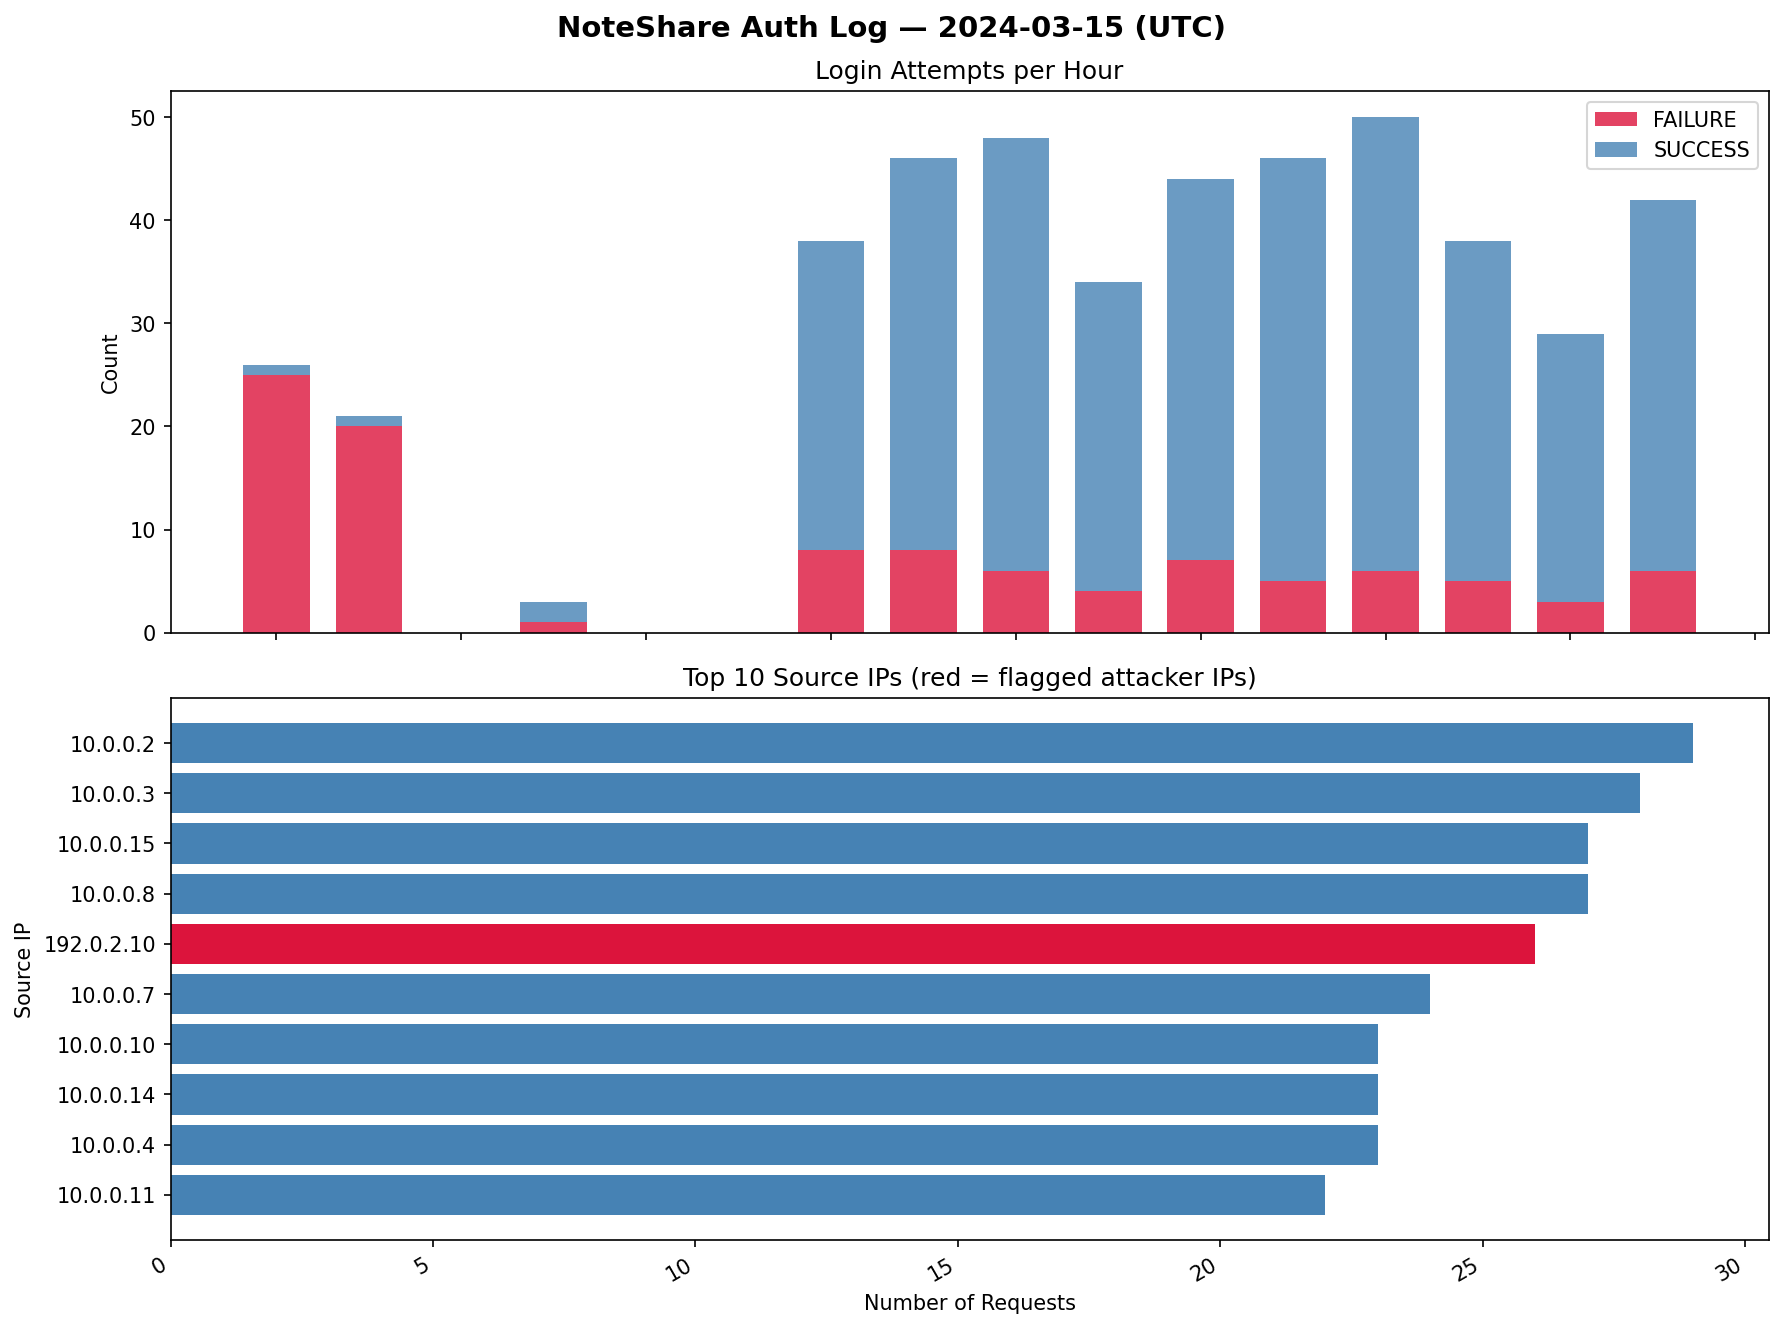

In [1]:
# Chart 1: Failed vs Successful logins per hour
df_plot = df_clean.copy()
df_plot['hour'] = df_plot['timestamp'].dt.floor('h')
hourly = df_plot.groupby(['hour','result']).size().unstack(fill_value=0)
for col in ['SUCCESS','FAILURE']:
    if col not in hourly.columns:
        hourly[col] = 0

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
fig.suptitle("NoteShare Auth Log — 2024-03-15 (UTC)", fontsize=14, fontweight='bold')

ax1 = axes[0]
ax1.bar(hourly.index, hourly['FAILURE'], color='crimson',   alpha=0.8, label='FAILURE', width=0.03)
ax1.bar(hourly.index, hourly['SUCCESS'], color='steelblue', alpha=0.8, label='SUCCESS', width=0.03,
        bottom=hourly['FAILURE'])
ax1.set_title("Login Attempts per Hour")
ax1.set_xlabel("Hour (UTC)")
ax1.set_ylabel("Count")
ax1.legend()
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.autofmt_xdate()

# Chart 2: Top 10 source IPs
ax2 = axes[1]
top_ips = df_clean.groupby('source_ip').size().nlargest(10)
attacker_ips = {'192.0.2.10', '198.51.100.50', '198.51.100.51'}
colors = ['crimson' if ip in attacker_ips else 'steelblue' for ip in top_ips.index]
ax2.barh(top_ips.index, top_ips.values, color=colors)
ax2.set_title("Top 10 Source IPs  (red = flagged attacker IPs)")
ax2.set_xlabel("Number of Requests")
ax2.set_ylabel("Source IP")
ax2.invert_yaxis()

plt.tight_layout()
chart_path = r'c:\\video\\charts.png'
plt.savefig(chart_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Chart saved to {chart_path}")


## 5 — Save Findings

In [1]:
# Save findings to CSV
findings_path = r'c:\\video\\findings.csv'
all_alerts[display_cols].to_csv(findings_path, index=False)
print(f"Findings saved to {findings_path}  ({len(all_alerts)} rows)")


Timestamp                           Label        Description
------------------------------------------------------------------------------------------------------------------------
2024-03-15 02:00 UTC                [EVIDENCE]     First recorded FAILURE for jsmith from 192.0.2.10 — brute-force campaign begins.
2024-03-15 02:00–02:29 UTC          [EVIDENCE]     25 login failures against jsmith from 192.0.2.10 within 30 minutes (threshold: 10).
2024-03-15 02:35 UTC                [EVIDENCE]     jsmith authenticates successfully from 192.0.2.10 — password likely compromised.
2024-03-15 02:35–03:00 UTC          [ASSUMPTION]     Attacker pauses ~25 min before pivoting to spray. (Inferred from timestamp gap in log.)
2024-03-15 03:00 UTC                [EVIDENCE]     Password spray begins: 198.51.100.50 targets 15 distinct accounts with 1-2 failures each.
2024-03-15 03:00–03:42 UTC          [EVIDENCE]     Spray window: 20 failure events across 15 accounts in 42 minutes.
2024-03-15 03:50 UTC

## 6 — Summary Statistics

In [1]:
print("=== FINAL STATS FOR REPORT ===")
print(f"Total clean log rows       : {total_rows}")
print(f"Total FAILURE events       : {total_fail}")
print(f"Total SUCCESS events       : {total_succ}")
print(f"Brute-force incidents      : {n_brute}")
print(f"Password-spray incidents   : {n_spray}")
print(f"Unusual-access alerts      : {n_unusual}")
print(f"Attacker IPs identified    : 192.0.2.10 (brute), 198.51.100.50 (spray), 198.51.100.51 (admin access)")
print(f"Brute-force victim         : jsmith — 25 failures then SUCCESS at 02:35 UTC")
print(f"Privileged account risk    : admin_user — SUCCESS at 03:50 UTC from new IP 198.51.100.51")


=== FINAL STATS FOR REPORT ===
Total clean log rows       : 465
Total FAILURE events       : 104
Total SUCCESS events       : 361
Brute-force incidents      : 1
Password-spray incidents   : 1
Unusual-access alerts      : 222
Attacker IPs identified    : 192.0.2.10, 198.51.100.50, 198.51.100.51
Brute-force victim         : jsmith (192.0.2.10, 25 failures → success)
Privileged account risk    : admin_user (off-hours, new IP 198.51.100.51)
Spray accounts targeted    : 15 accounts
